<center><h1>Yu_Stella_HW4</h1></center>
<br>
<br>

Name: Stella Yu
<br>
Github Username: syu35435-cmyk
<br>
USC ID: 3420585291

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.utils import resample
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB

Get the AReM Data Set

In [2]:
columns = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

df = pd.read_csv("data/AReM/AReM/bending1/dataset1.csv",
                 skiprows=4, usecols=range(7))

df.columns = columns
df.head()

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,39.25,0.43,22.75,0.43,33.75,1.3
1,250,39.25,0.43,23.00,0.00,33.00,0.0
2,500,39.25,0.43,23.25,0.43,33.00,0.0
3,750,39.50,0.50,23.00,0.71,33.00,0.0
4,1000,39.50,0.50,24.00,0.00,33.00,0.0


### (b) Splitting Data

In [3]:
activities = ["bending1", "bending2", "cycling", "lying","sitting", "standing", "walking"]

train_data = []
test_data = []

for activity in activities:
    folder = "data/AReM/AReM/" + activity

    for file in os.listdir(folder):

        if activity == "bending1" or activity == "bending2":
            if file == "dataset1.csv" or file == "dataset2.csv":
                test_data.append(folder + "/" + file)
            elif file.endswith(".csv"):
                train_data.append(folder + "/" + file)
    
        else:
            if file == "dataset1.csv" or file == "dataset2.csv" or file == "dataset3.csv":
                test_data.append(folder + "/" + file)
            elif file.endswith(".csv"):
                train_data.append(folder + "/" + file)

### (c) Feature Extraction

In [4]:
rows = []

files = train_data + test_data

time_series = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

for file in files:
    df = pd.read_csv(file, skiprows=4, usecols=range(7))

    row = []

    # extract features
    for column in time_series:
        row.append(df[column].min())
        row.append(df[column].max())
        row.append(df[column].mean())
        row.append(df[column].median())
        row.append(df[column].std())
        row.append(df[column].quantile(0.25))
        row.append(df[column].quantile(0.75))

    rows.append(row)

columns = []

for i in range(1, 7):
    columns.append("min" + str(i))
    columns.append("max" + str(i))
    columns.append("mean" + str(i))
    columns.append("median" + str(i))
    columns.append("std" + str(i))
    columns.append("1st_quart" + str(i))
    columns.append("3rd_quart" + str(i))

feature_df = pd.DataFrame(rows, columns=columns)

feature_df

results = []

for column in feature_df.columns:
    data = feature_df[column]
    std = data.std()

    bootstrap_std = []

    for i in range(1000):
        sample = resample(data)
        bootstrap_std.append(sample.std())

    bootstrap_std.sort()

    # 90% confidence interval
    lower = bootstrap_std[49]
    upper = bootstrap_std[949]

    results.append([std, lower, upper])

std_df = pd.DataFrame(
    results,
    index=feature_df.columns,
    columns=["Standard Deviation", "Lower Bound", "Upper Bound"]
)

std_df

,Standard Deviation,Lower Bound,Upper Bound
min1,9.624011,8.297811,10.819754
max1,4.207745,3.156788,5.100973
mean1,5.276431,4.649978,5.837838
median1,5.386624,4.717351,5.953141
std1,1.771282,1.579570,1.947334
1st_quart1,6.127846,5.518107,6.616956
3rd_quart1,5.031028,4.221775,5.772197
min2,0.000000,0.000000,0.000000
max2,5.059656,4.630341,5.400289
mean2,1.577908,1.401613,1.710378


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

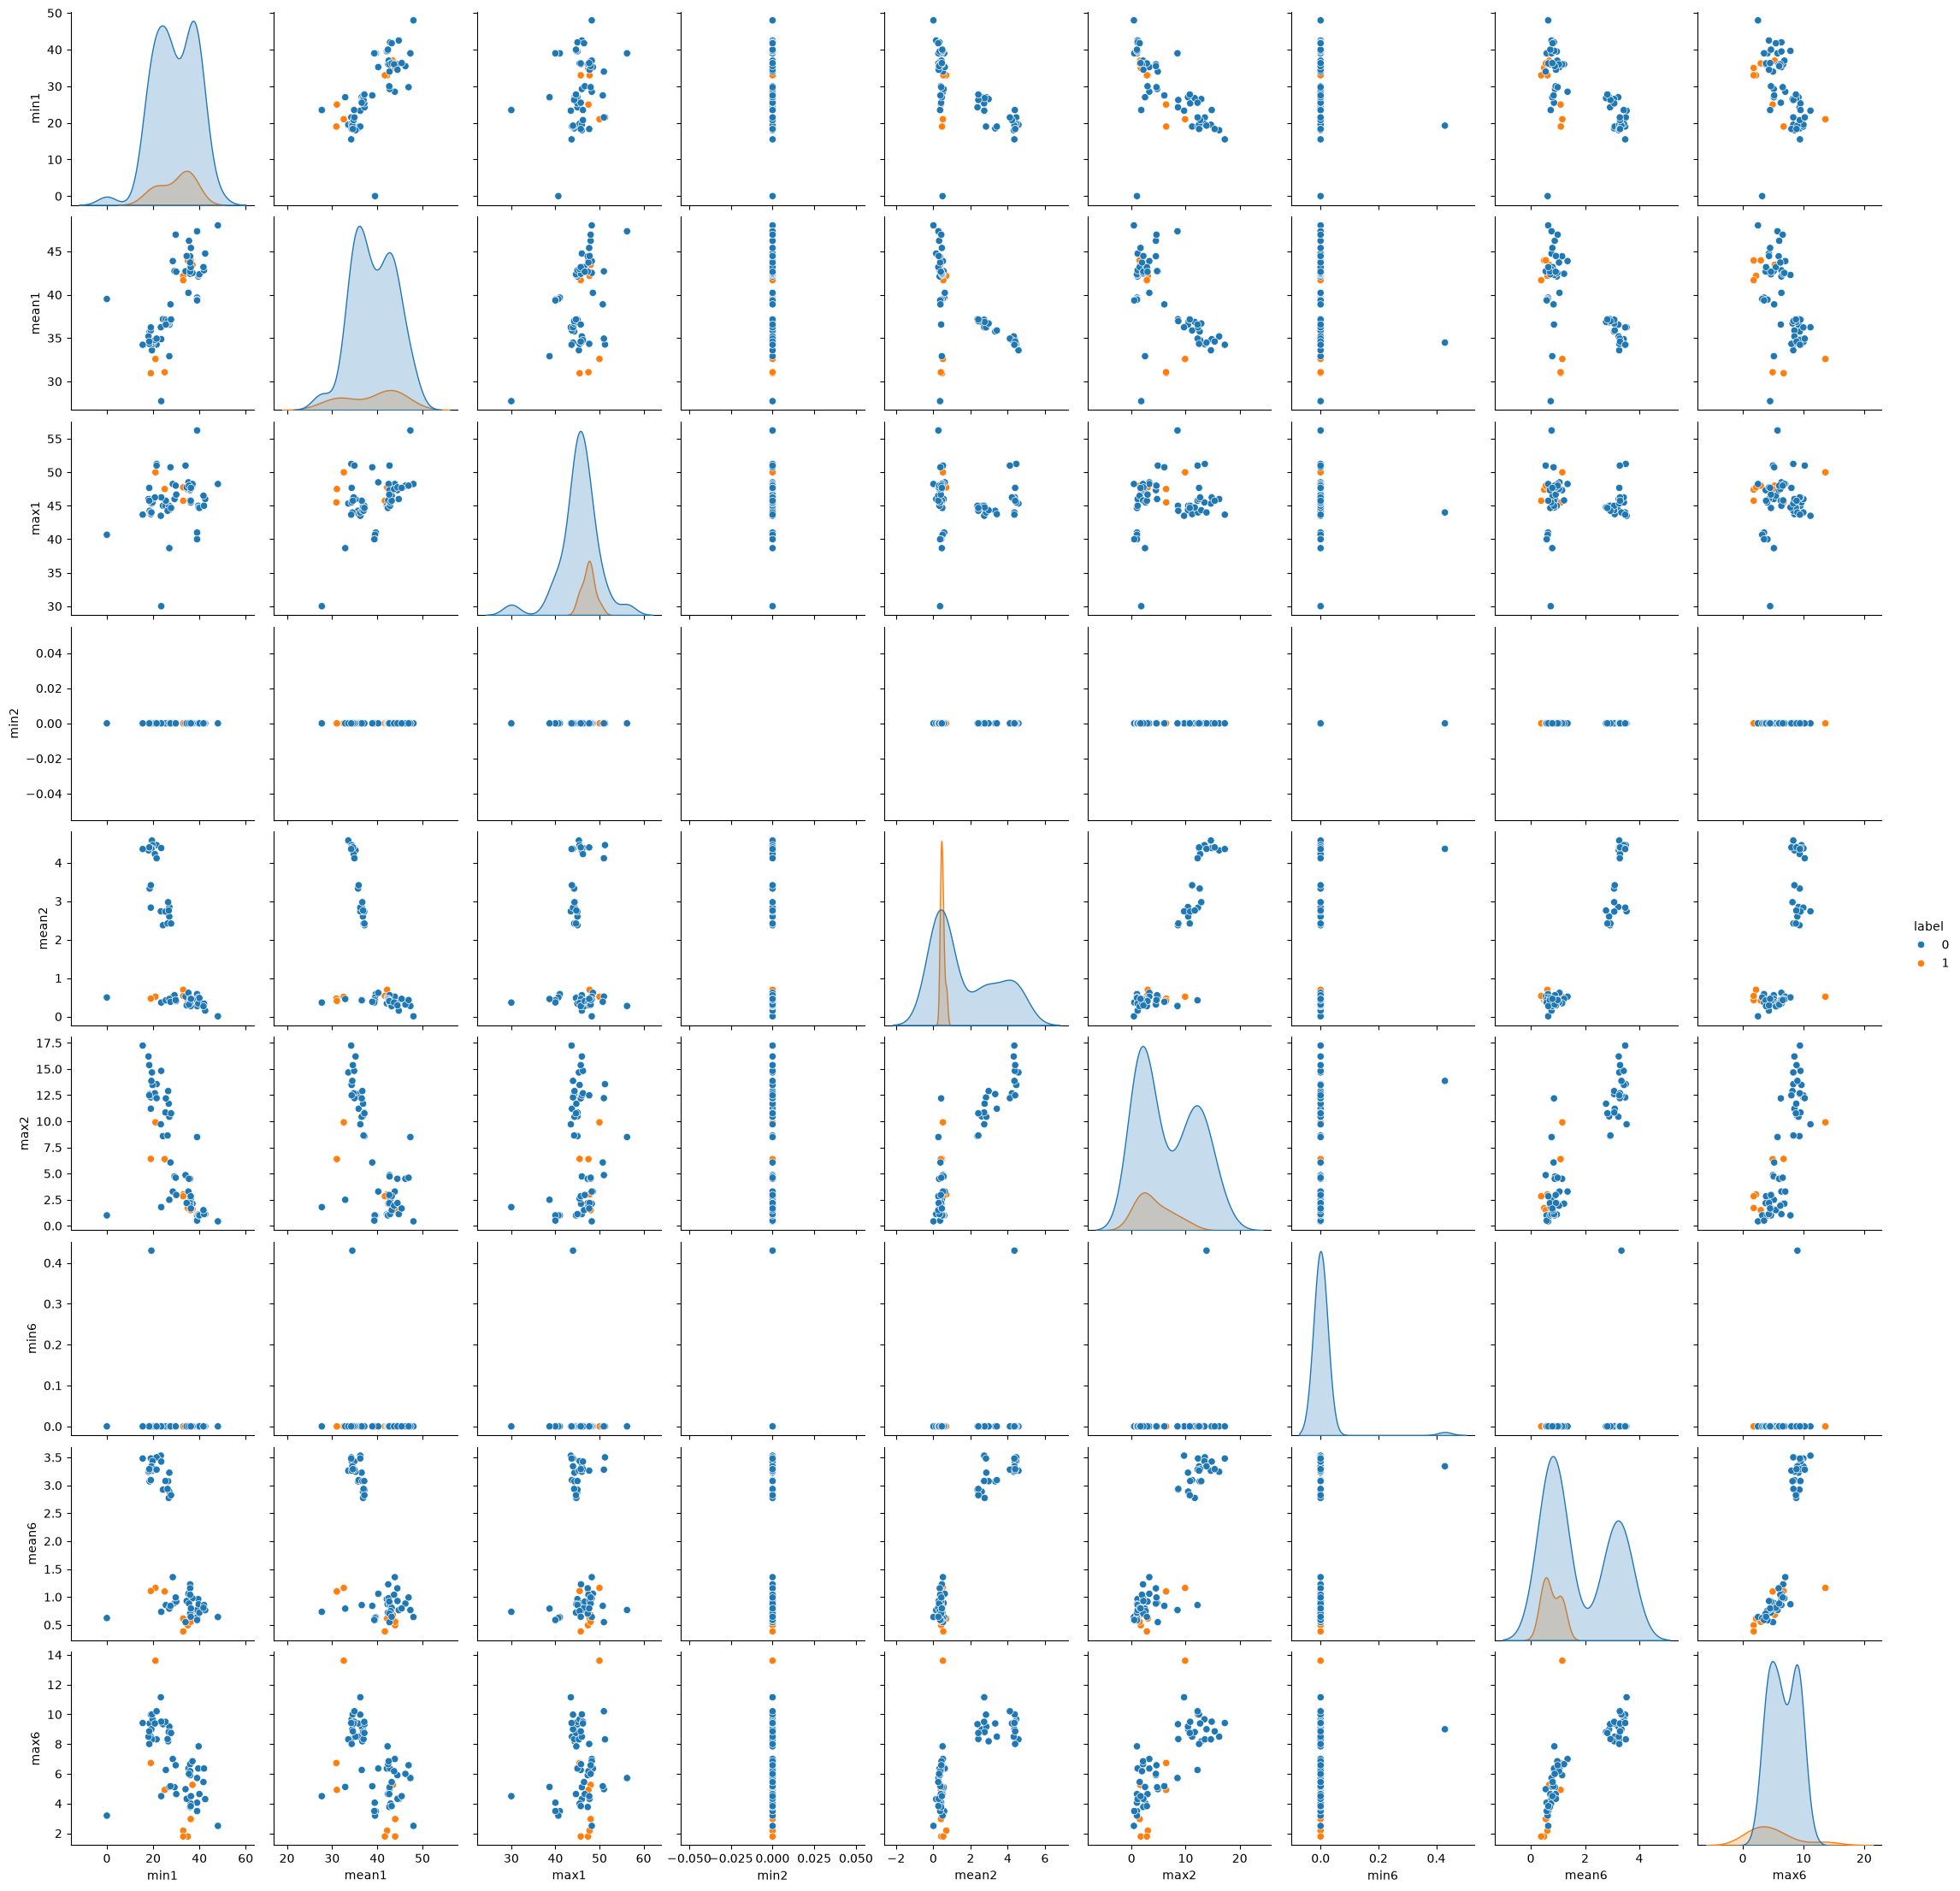

In [5]:
labels = []

for file in train_data:
    if "bending" in file:
        labels.append(1)
    else:
        labels.append(0)

X_train = feature_df.iloc[:69].copy()
X_train["label"] = labels

variables = ["min1", "mean1", "max1","min2", "mean2", "max2", "min6", "mean6", "max6"]

sns.pairplot(X_train, vars=variables, hue="label")

plt.show()

#### ii. Splitted Plots

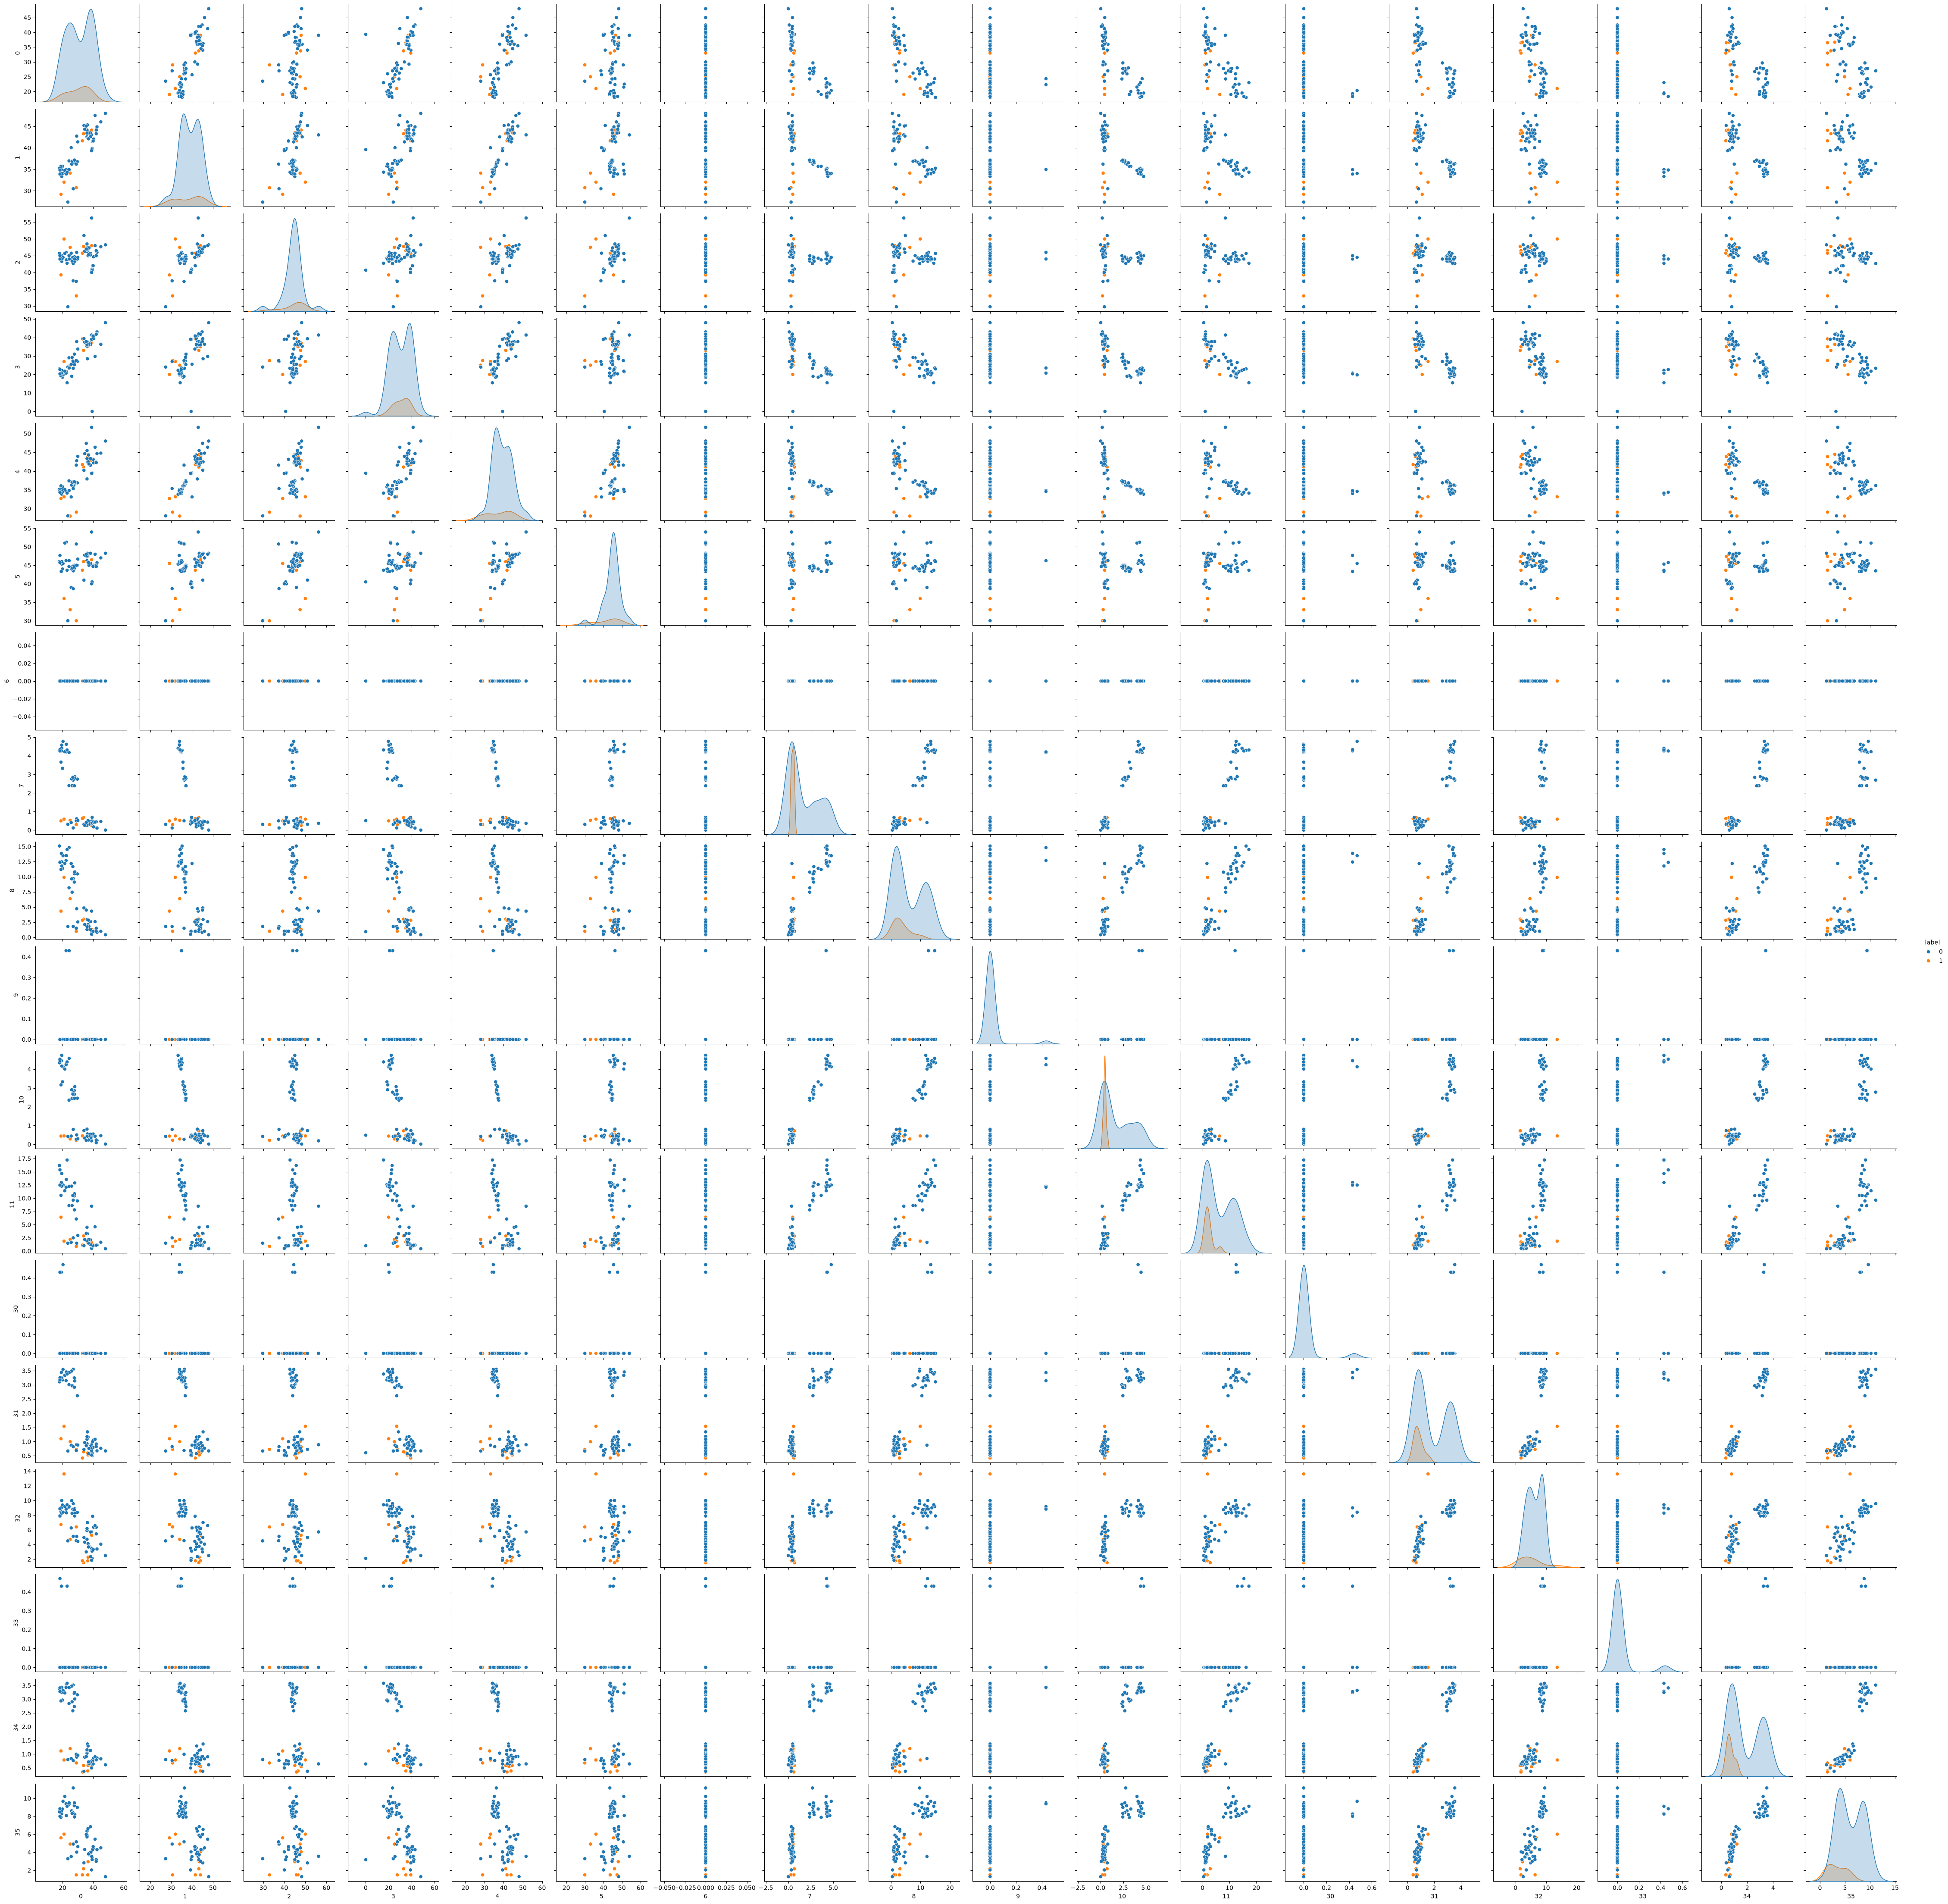

In [6]:
rows = []

for file in train_data:
    if "bending2/dataset4.csv" in file:
        df = pd.read_csv(file, skiprows=5, sep=r"\s+", header=None)
    else:
        df = pd.read_csv(file, skiprows=4, usecols=range(7))

    row = []

    for column in range(1, 7):
        data = pd.to_numeric(df.iloc[:, column])

        parts = np.array_split(data, 2)

        for part in parts:
            row.append(part.min())
            row.append(part.mean())
            row.append(part.max())

    rows.append(row)
    
split_df = pd.DataFrame(rows)
split_df["label"] = labels

sns.pairplot(split_df, vars=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 30, 31, 32, 33, 34, 35], hue="label")
plt.show()



I do not see any considerable differences after splitting. The plot is more detailed but the results are similar. 

#### iii. Time Series Segments

In [7]:
def extract_features(files, l):
    rows = []

    for file in files:
        if "bending2/dataset4.csv" in file:
            df = pd.read_csv(file, skiprows=5, sep=r"\s+", header=None)
        else:
            df = pd.read_csv(file, skiprows=4, usecols=range(7))

        row = []

        for column in range(1, 7):
            data = pd.to_numeric(df.iloc[:, column])
            parts = np.array_split(data, l)

            for part in parts:
                row.append(part.min())
                row.append(part.mean())
                row.append(part.max())

        rows.append(row)

    return pd.DataFrame(rows)

In [8]:
y_train = np.array(labels)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

best_score = 0
best_l = 0
best_p = 0

# Find best l and p
for l in range(1, 21):
    # X_train = extract_features(l)
    X_train = extract_features(train_data, l)

    print("l =", l)

    for p in [1, 2, 3, 5, 10, 15, 20, 50]:
        if p > X_train.shape[1]:
            continue

        model = LogisticRegression(C=1000000, max_iter=100)

        pipeline = make_pipeline( SimpleImputer(strategy="median"),StandardScaler(), 
              RFE(model, n_features_to_select=p),
              LogisticRegression(C=1000000, max_iter=100)
        )

        scores = cross_val_score(pipeline, X_train, y_train, cv=cv)
        accuracy = scores.mean()

        if accuracy > best_score:
            best_score = accuracy
            best_l = l
            best_p = p

print("Best l:", best_l)
print("Best p:", best_p)
print("Best Accuracy:", round(best_score, 4))

l = 1
l = 2
l = 3
l = 4
l = 5
l = 6
l = 7
l = 8
l = 9
l = 10
l = 11
l = 12
l = 13
l = 14
l = 15
l = 16
l = 17
l = 18
l = 19
l = 20
Best l: 1
Best p: 10
Best Accuracy: 1.0


#### iv. Confusion Matrix

Confusion Matrix: [[60  0]
 [ 0  9]]
AUC: 1.0


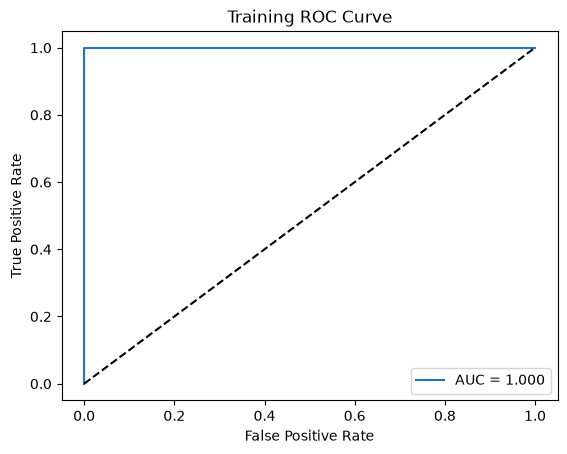

Intercept: [-10.57968461]
Coefficients: [[-2.26843668 -1.41688392 -2.77293823 -1.54645575 -2.27090214 -1.97711014
   1.78177743  4.58942095  2.53127846  6.02390642]]
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                   69
Model:                            GLM   Df Residuals:                       58
Model Family:                Binomial   Df Model:                           10
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.8351e-09
Date:                Sun, 18 Oct 2026   Deviance:                   3.6702e-09
Time:                        19:32:11   Pearson chi2:                 1.84e-09
No. Iterations:                    24   Pseudo R-squ. (CS):             0.5390
Covariance Type:            nonrobust                                         
                 coef    std err          z 

C:\Users\5809s\anaconda3\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
C:\Users\5809s\anaconda3\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
C:\Users\5809s\anaconda3\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
C:\Users\5809s\anaconda3\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparat

In [9]:
X_train = extract_features(train_data, best_l)

pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    RFE(LogisticRegression(C=1000000, max_iter=100),
        n_features_to_select=best_p),
    LogisticRegression(C=1000000, max_iter=100)
)

pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_train)
cm = confusion_matrix(y_train, y_pred)

print("Confusion Matrix:", cm)

y_prob = pipeline.predict_proba(X_train)[:, 1]

fpr, tpr, _ = roc_curve(y_train, y_prob)
auc = roc_auc_score(y_train, y_prob)

print("AUC:", auc)

plt.plot(fpr, tpr, label="AUC = %.3f" % auc)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training ROC Curve")
plt.legend()
plt.show()

model = pipeline.named_steps["logisticregression"]

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

X_selected = pipeline[:-1].transform(X_train)

X_selected = sm.add_constant(X_selected)

model = sm.GLM(y_train, X_selected, family=sm.families.Binomial())
result = model.fit()

print(result.summary())

#### v. Test Classifier

In [10]:
X_test = extract_features(test_data, best_l)

y_test = []

for file in test_data:
    if "bending" in file:
        y_test.append(1)
    else:
        y_test.append(0)

y_test_pred = pipeline.predict(X_test)

print(y_test)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("CV Accuracy:", best_score)
print("Test Accuracy:", test_accuracy)

[1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
CV Accuracy: 1.0
Test Accuracy: 1.0


#### vi. Separation

Yes, the classes seem to be well-separated because the model achieved 100% training accuracy.

#### vii. Imbalance

Confusion Matrix:
[[60  0]
 [ 0  9]]
AUC: 1.0


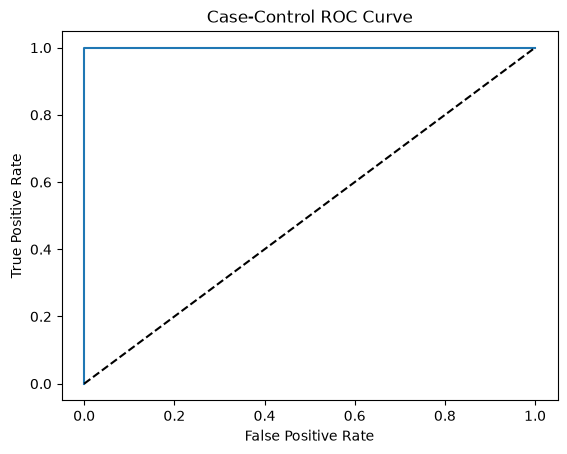

In [11]:
# Balance the training data
X_train = extract_features(train_data, best_l)

X_bending = resample( X_train[y_train == 1], replace=True, n_samples=60, random_state=42)

X = pd.concat([X_train[y_train == 0], X_bending])
y = np.array([0] * 60 + [1] * 60)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X, y)

y_pred = model.predict(X_train)
y_prob = model.predict_proba(X_train)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_train, y_pred))

print("AUC:", roc_auc_score(y_train, y_prob))

fpr, tpr, _ = roc_curve(y_train, y_prob)

plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Case-Control ROC Curve")
plt.show()


### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

best_score = 0
best_l = 0
best_C = 0

for l in range(1, 21):
    X_train = extract_features(train_data, l)

    for C in [0.01, 0.1, 1, 10, 100]:
        model = LogisticRegression(
            l1_ratio=1, solver="liblinear", C=C, max_iter=100
        )

        pipeline = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            model
        )

        scores = cross_val_score(pipeline, X_train, y_train, cv=cv)
        accuracy = scores.mean()

        if accuracy > best_score:
            best_score = accuracy
            best_l = l
            best_C = C

print("Best l:", best_l)
print("Best C:", best_C)
print("Best CV Accuracy:", best_score)

X_train = extract_features(train_data, best_l)

model = LogisticRegression(
    l1_ratio=1, solver="liblinear", C=best_C, max_iter=100
)

pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    model
)

pipeline.fit(X_train, y_train)

coefficients = pipeline.named_steps["logisticregression"].coef_[0]

print("Number of selected features:", np.sum(coefficients != 0))
print("Training Accuracy:", pipeline.score(X_train, y_train))

# Best l: 1
# Best C: 100
# Best Accuracy: 1.0
# Number of selected features: 10
# Training Accuracy: 1.0

Best l: 1
Best C: 100
Best CV Accuracy: 1.0
Number of selected features: 10
Training Accuracy: 1.0


#### ii. Comparison

Both RFE-based logistic regression and L1-penalized logistic regression achieved 100% cross-validation accuracy and 100% training accuracy. Both methods selected 10 features, so neither method demonstrated better classification performance in this experiment.

However, L1-penalized logistic regression is easier to implement because it performs feature selection automatically by shrinking some coefficients to zero. In contrast, RFE requires a separate feature-selection procedure and cross-validation to determine the number of features to retain.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [13]:
###
y_train_multi = []

for file in train_data:
    activity = os.path.basename(os.path.dirname(file))
    y_train_multi.append(activity)

y_train_multi = np.array(y_train_multi)

warnings.filterwarnings("ignore", category=ConvergenceWarning)

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

best_score = 0
best_l = 0
best_C = 0

for l in range(1, 21):
    X_train = extract_features(train_data, l)
    for C in [0.01, 0.1, 1, 10, 100]:
        model = LogisticRegression(
            l1_ratio=1, solver="saga", C=C,
            max_iter=100, random_state=42
        )

        pipeline = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            model
        )

        scores = cross_val_score(pipeline, X_train, y_train_multi, cv=cv)
        accuracy = scores.mean()

        if accuracy > best_score:
            best_score = accuracy
            best_l = l
            best_C = C

print("Best l:", best_l)
print("Best C:", best_C)
print("Best CV Accuracy:", best_score)


Best l: 1
Best C: 100
Best CV Accuracy: 0.8684640522875817


Test Accuracy: 0.9473684210526315
Test Error: 0.052631578947368474
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 3 0 0]
 [0 0 0 1 0 2 0]
 [0 0 0 0 0 0 3]]


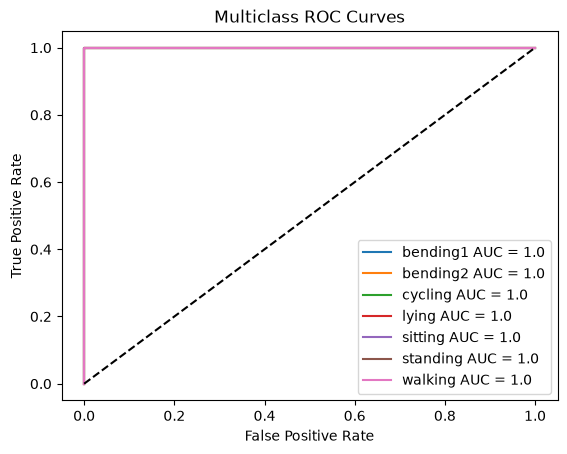

In [14]:
X_train = extract_features(train_data, best_l)

model = LogisticRegression(
    l1_ratio=1, solver="saga", C=best_C,
    max_iter=100, random_state=42
)

pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    model
)

pipeline.fit(X_train, y_train_multi)


y_test_multi = []

for file in test_data:
    activity = os.path.basename(os.path.dirname(file))
    y_test_multi.append(activity)

y_test_multi = np.array(y_test_multi)

X_test = extract_features(test_data, best_l)

y_pred = pipeline.predict(X_test)

test_accuracy = accuracy_score(y_test_multi, y_pred)
test_error = 1 - test_accuracy

print("Test Accuracy:", test_accuracy)
print("Test Error:", test_error)


cm = confusion_matrix(y_test_multi, y_pred)
print(cm)

y_prob = pipeline.predict_proba(X_test)

for i in range(len(pipeline.classes_)):
    y_binary = (y_test_multi == pipeline.classes_[i]).astype(int)

    fpr, tpr, _ = roc_curve(y_binary, y_prob[:, i])
    roc_auc = roc_auc_score(y_binary, y_prob[:, i])

    plt.plot(fpr, tpr, label=str(pipeline.classes_[i]) + " AUC = " + str(round(roc_auc, 2)))

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves")
plt.legend()
plt.show()

#### ii. Naive Bayes

In [15]:
best_score = 0
best_l = 0

for l in range(1, 21):
    X_train = extract_features(train_data, l)

    model = GaussianNB()

    pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        model
    )

    scores = cross_val_score(pipeline, X_train, y_train_multi, cv=cv)
    accuracy = scores.mean()

    if accuracy > best_score:
        best_score = accuracy
        best_l = l

print("Best l:", best_l)
print("Best Accuracy:", best_score)

X_train = extract_features(train_data, best_l)

model = GaussianNB()

pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    model
)

pipeline.fit(X_train, y_train_multi)


X_test = extract_features(test_data, best_l)

y_pred = pipeline.predict(X_test)

test_accuracy = accuracy_score(y_test_multi, y_pred)
test_error = 1 - test_accuracy

print("Test Accuracy:", test_accuracy)
print("Test Error:", test_error)


Best l: 2
Best Accuracy: 0.826797385620915
Test Accuracy: 0.8421052631578947
Test Error: 0.1578947368421053


In [16]:
best_score = 0
best_l = 0

for l in range(1, 21):
    X_train = extract_features(train_data, l)

    model = MultinomialNB()

    pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        MinMaxScaler(),
        model
    )

    scores = cross_val_score(pipeline, X_train, y_train_multi, cv=cv)
    accuracy = scores.mean()

    if accuracy > best_score:
        best_score = accuracy
        best_l = l

print("Best l:", best_l)
print("Best Accuracy:", best_score)

X_train = extract_features(train_data, best_l)

model = MultinomialNB()

pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    MinMaxScaler(),
    model
)

pipeline.fit(X_train, y_train_multi)

X_test = extract_features(test_data, best_l)

y_pred = pipeline.predict(X_test)

test_accuracy = accuracy_score(y_test_multi, y_pred)
test_error = 1 - test_accuracy

print("Test Accuracy:", test_accuracy)
print("Test Error:", test_error)

Best l: 1
Best Accuracy: 0.7377450980392157
Test Accuracy: 0.6842105263157895
Test Error: 0.3157894736842105


#### ii. Comparison

L1-penalized multinomial logistic regression performed the best by achieving accuracy of 94.74%.  Gaussian Naive Bayes achieved 84.21% accuracy, while Multinomial Naive Bayes achieved 68.42%. Therefore, logistic regression performed the best out of all three models.

## 3. ISLR 4.8.3

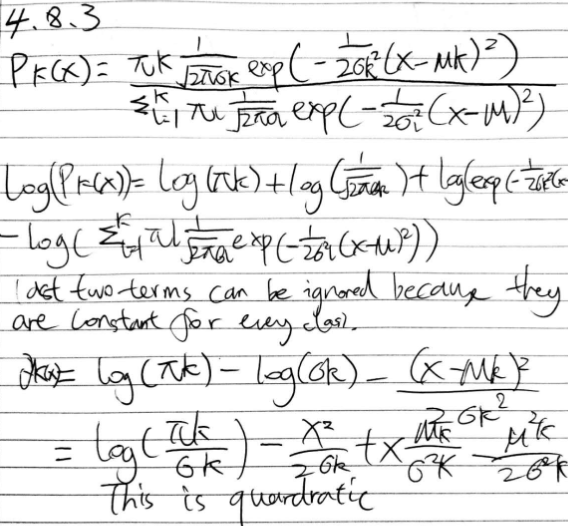

## 4. ISLR 4.8.7

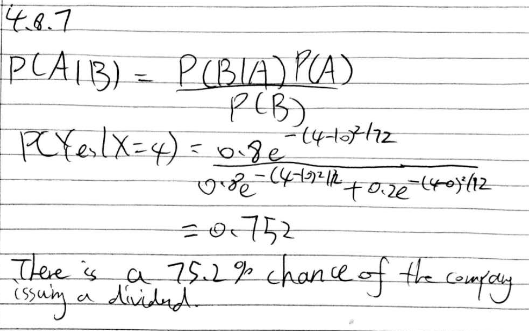

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9